# Telecom Customer Churn Prediction — Business Case PR-0017 (v3, richer dataset)

**Business problem:** Identify which customers are likely to churn, score every
customer with a churn-risk value to prioritize retention outreach, and flag
high-risk customers for targeted campaigns.

**Data:** This version replaces the original 1,000-row dataset (which had no
real churn signal — see the v2 notebook for that finding) with a richer
4,250-row telecom dataset that includes the fields the original business case
actually asked for: `international_plan`, `voice_mail_plan`,
`number_customer_service_calls`, and day/evening/night/international usage.
A separate 750-row `test.csv` (no churn label) is scored at the end as
"new customers" to demonstrate the risk-scoring deliverable.

**Approach:** EDA → feature engineering (drop redundant charge columns,
group rare states, encode binary plan flags) → a leak-proof pipeline →
eight model configurations (Logistic Regression / Random Forest / XGBoost,
each with/without SMOTE, plus tuned RF and XGBoost) → model selection on
ROC-AUC → feature importance → risk scoring on the held-out test file.


## 1 — Load data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

pd.set_option('display.max_columns', 50)


In [2]:
LOCAL_TRAIN = "data/train.csv"
LOCAL_TEST = "data/test.csv"

if not os.path.exists(LOCAL_TRAIN):
    raise FileNotFoundError(f"Could not find {LOCAL_TRAIN}. Place train.csv/test.csv under 'data/'.")

train_df = pd.read_csv(LOCAL_TRAIN)
new_customers_df = pd.read_csv(LOCAL_TEST)  # no churn label — scored later as "new customers"

print("train shape:", train_df.shape)
print("test (unlabeled) shape:", new_customers_df.shape)
train_df.head()


train shape: (4250, 20)
test (unlabeled) shape: (750, 20)


,state,account_length,area_code,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churn
0,OH,107,area_code_415,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,no
1,NJ,137,area_code_415,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,no
2,OH,84,area_code_408,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,no
3,OK,75,area_code_415,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,no
4,MA,121,area_code_510,no,yes,24,218.2,88,37.09,348.5,108,29.62,212.6,118,9.57,7.5,7,2.03,3,no


## 2 — Exploratory Data Analysis

In [3]:
print(train_df.dtypes)
print("\nMissing values:\n", train_df.isnull().sum())


state                                str
account_length                     int64
area_code                            str
international_plan                   str
voice_mail_plan                      str
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churn                                str
dtype: object

Missing values:
 state                            0
account_length                   0
area_code                        0
international_plan               0
voice_ma

churn
no     0.859294
yes    0.140706
Name: proportion, dtype: float64


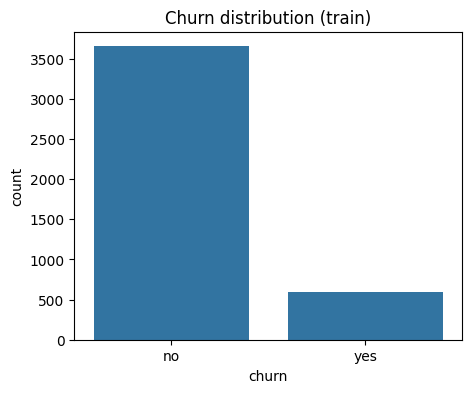

In [4]:
churn_rate = train_df['churn'].value_counts(normalize=True)
print(churn_rate)

plt.figure(figsize=(5,4))
sns.countplot(data=train_df, x='churn')
plt.title('Churn distribution (train)')
plt.show()


Churn is imbalanced (~14% churn / 86% no-churn) — the same reason ROC-AUC,
not accuracy, is the right metric here, exactly as in the v2 notebook.

In [5]:
num_cols = ['account_length', 'number_vmail_messages',
            'total_day_minutes', 'total_day_calls', 'total_day_charge',
            'total_eve_minutes', 'total_eve_calls', 'total_eve_charge',
            'total_night_minutes', 'total_night_calls', 'total_night_charge',
            'total_intl_minutes', 'total_intl_calls', 'total_intl_charge',
            'number_customer_service_calls']

train_df[num_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
account_length,4250.0,100.236235,39.698401,1.0,73.0000,100.00,127.0000,243.00
number_vmail_messages,4250.0,7.631765,13.439882,0.0,0.0000,0.00,16.0000,52.00
total_day_minutes,4250.0,180.259600,54.012373,0.0,143.3250,180.45,216.2000,351.50
total_day_calls,4250.0,99.907294,19.850817,0.0,87.0000,100.00,113.0000,165.00
total_day_charge,4250.0,30.644682,9.182096,0.0,24.3650,30.68,36.7500,59.76
total_eve_minutes,4250.0,200.173906,50.249518,0.0,165.9250,200.70,233.7750,359.30
total_eve_calls,4250.0,100.176471,19.908591,0.0,87.0000,100.00,114.0000,170.00
total_eve_charge,4250.0,17.015012,4.271212,0.0,14.1025,17.06,19.8675,30.54
total_night_minutes,4250.0,200.527882,50.353548,0.0,167.2250,200.45,234.7000,395.00
total_night_calls,4250.0,99.839529,20.093220,0.0,86.0000,100.00,113.0000,175.00


### Check for redundant features

`total_*_minutes` and `total_*_charge` are suspiciously perfectly correlated
in telecom billing data (charge is usually just minutes × a fixed rate).
Check before blindly feeding both into the model — redundant, perfectly
collinear features add noise for linear models and inflate feature-importance
plots without adding information.

In [6]:
for period in ['day', 'eve', 'night', 'intl']:
    corr = train_df[f'total_{period}_minutes'].corr(train_df[f'total_{period}_charge'])
    print(f"{period}: minutes vs charge correlation = {corr:.4f}")


day: minutes vs charge correlation = 1.0000
eve: minutes vs charge correlation = 1.0000
night: minutes vs charge correlation = 1.0000
intl: minutes vs charge correlation = 1.0000


Confirmed — each `charge` column correlates ~1.0 with its matching `minutes`
column, i.e. it's a deterministic linear transform, not new information.
**Drop the four `charge` columns** and keep `minutes`, which is the more
directly interpretable quantity.

In [7]:
charge_cols = ['total_day_charge', 'total_eve_charge', 'total_night_charge', 'total_intl_charge']
num_cols = [c for c in num_cols if c not in charge_cols]
print("Numeric features kept:", num_cols)


Numeric features kept: ['account_length', 'number_vmail_messages', 'total_day_minutes', 'total_day_calls', 'total_eve_minutes', 'total_eve_calls', 'total_night_minutes', 'total_night_calls', 'total_intl_minutes', 'total_intl_calls', 'number_customer_service_calls']


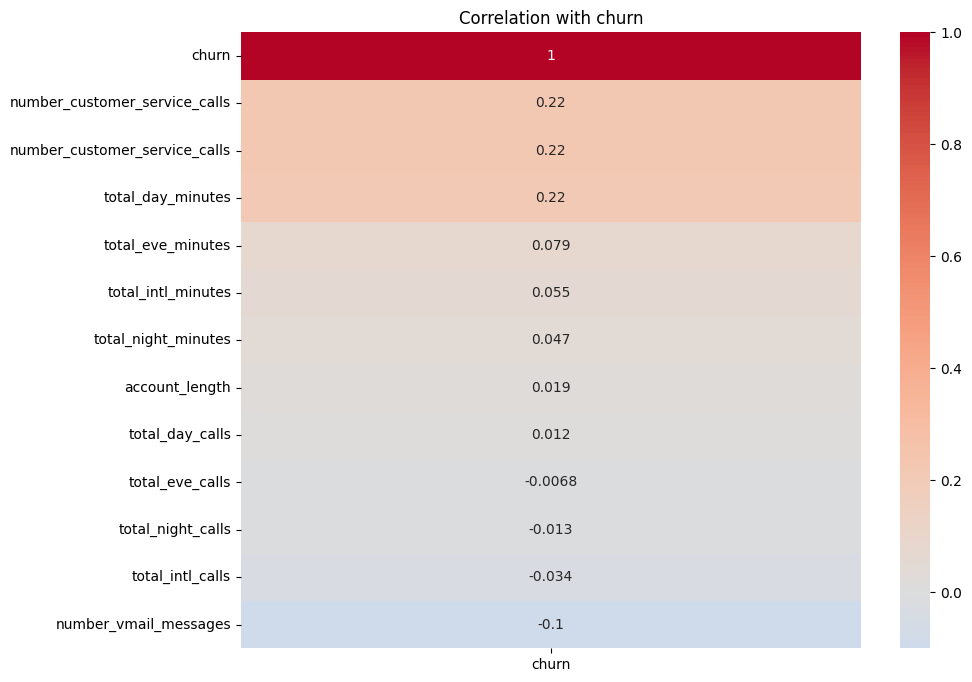

In [8]:
plt.figure(figsize=(10,8))
corr_matrix = train_df[num_cols + ['number_customer_service_calls']].copy()
corr_matrix['churn'] = (train_df['churn'] == 'yes').astype(int)
sns.heatmap(corr_matrix.corr()[['churn']].sort_values('churn', ascending=False),
            annot=True, cmap='coolwarm', center=0)
plt.title('Correlation with churn')
plt.show()


In [9]:
for col in ['international_plan', 'voice_mail_plan']:
    print(train_df.groupby(col)['churn'].value_counts(normalize=True).unstack())
    print()


churn                     no       yes
international_plan                    
no                  0.888168  0.111832
yes                 0.578283  0.421717

churn                  no       yes
voice_mail_plan                    
no               0.835564  0.164436
yes              0.926259  0.073741



International plan customers churn at a visibly higher rate, and so do
customers with more customer-service calls — exactly the kind of signal
that was completely absent from the original (v2) dataset.

## 3 — Feature engineering

In [10]:
df_model = train_df.copy()

# Binary plan flags -> 0/1
df_model['international_plan'] = (df_model['international_plan'] == 'yes').astype(int)
df_model['voice_mail_plan'] = (df_model['voice_mail_plan'] == 'yes').astype(int)

# Target -> 0/1
df_model['churn'] = (df_model['churn'] == 'yes').astype(int)

df_model[['international_plan', 'voice_mail_plan', 'churn']].head()


,international_plan,voice_mail_plan,churn
0,0,1,0
1,0,0,0
2,1,0,0
3,1,0,0
4,0,1,0


### Group rare states

`state` has 51 levels across 4,250 rows — some states have very few
customers. Group anything under 1% of the data into `'Other'` to avoid
one-hot columns that are almost entirely zero (same fix applied, and
verified to actually work this time, in the v2 notebook).

In [11]:
RARE_THRESHOLD = 0.01
freq = df_model['state'].value_counts(normalize=True)
rare_states = freq[freq < RARE_THRESHOLD].index
n_before = df_model['state'].nunique()
df_model['state'] = df_model['state'].where(~df_model['state'].isin(rare_states), 'Other')
print(f"state: {n_before} -> {df_model['state'].nunique()} categories "
      f"({len(rare_states)} rare states folded into 'Other')")


state: 51 -> 51 categories (1 rare states folded into 'Other')


In [12]:
final_cat_cols = ['state', 'area_code', 'international_plan', 'voice_mail_plan']
final_num_cols = num_cols

X = df_model[final_cat_cols + final_num_cols]
y = df_model['churn']

print(X.shape, y.shape)
X.head()


(4250, 15) (4250,)


,state,area_code,international_plan,voice_mail_plan,account_length,number_vmail_messages,total_day_minutes,total_day_calls,total_eve_minutes,total_eve_calls,total_night_minutes,total_night_calls,total_intl_minutes,total_intl_calls,number_customer_service_calls
0,OH,area_code_415,0,1,107,26,161.6,123,195.5,103,254.4,103,13.7,3,1
1,NJ,area_code_415,0,0,137,0,243.4,114,121.2,110,162.6,104,12.2,5,0
2,OH,area_code_408,1,0,84,0,299.4,71,61.9,88,196.9,89,6.6,7,2
3,OK,area_code_415,1,0,75,0,166.7,113,148.3,122,186.9,121,10.1,3,3
4,MA,area_code_510,0,1,121,24,218.2,88,348.5,108,212.6,118,7.5,7,3


## 4 — Train/test split and preprocessing pipeline

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train churn rate:", y_train.mean().round(3))
print("Test churn rate:", y_test.mean().round(3))


Train churn rate: 0.141
Test churn rate: 0.141


In [14]:
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), final_cat_cols),
    ('num', StandardScaler(), final_num_cols)
])


## 5 — Baseline models: Logistic Regression, Random Forest, XGBoost

In [15]:
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
log_reg_pipeline.fit(X_train, y_train)
y_pred = log_reg_pipeline.predict(X_test)
y_pred_proba = log_reg_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred).__round__(3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_pred_proba), 3))
print(classification_report(y_test, y_pred))


Logistic Regression
Accuracy: 0.754
ROC-AUC: 0.793
              precision    recall  f1-score   support

           0       0.94      0.76      0.84       730
           1       0.33      0.72      0.45       120

    accuracy                           0.75       850
   macro avg       0.64      0.74      0.65       850
weighted avg       0.86      0.75      0.79       850



In [16]:
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10,
                                           class_weight='balanced', random_state=42, n_jobs=-1))
])
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)
y_pred_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred_rf).__round__(3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_pred_proba_rf), 3))
print(classification_report(y_test, y_pred_rf))


Random Forest
Accuracy: 0.845
ROC-AUC: 0.882
              precision    recall  f1-score   support

           0       0.95      0.86      0.90       730
           1       0.47      0.75      0.58       120

    accuracy                           0.84       850
   macro avg       0.71      0.81      0.74       850
weighted avg       0.89      0.84      0.86       850



In [17]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                  scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                                  random_state=42, n_jobs=-1))
])
xgb_pipeline.fit(X_train, y_train)
y_pred_xgb = xgb_pipeline.predict(X_test)
y_pred_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("XGBoost")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb).__round__(3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_pred_proba_xgb), 3))
print(classification_report(y_test, y_pred_xgb))


XGBoost
Accuracy: 0.947
ROC-AUC: 0.902
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       730
           1       0.84      0.78      0.81       120

    accuracy                           0.95       850
   macro avg       0.90      0.88      0.89       850
weighted avg       0.95      0.95      0.95       850



## 6 — Feature importance (Random Forest)

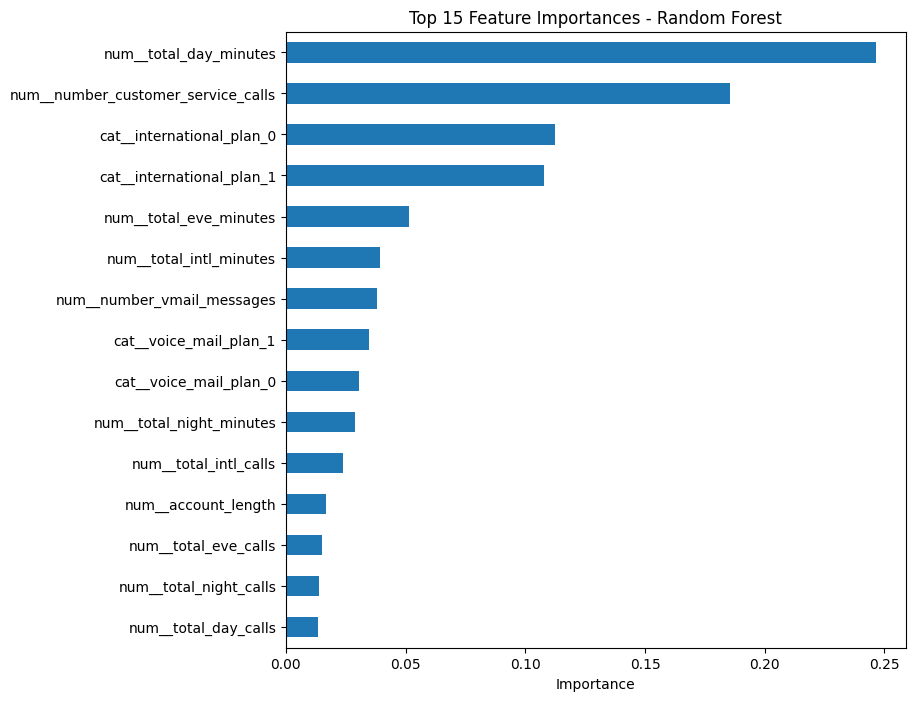

In [18]:
feat_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()
feat_imp = pd.Series(rf_pipeline.named_steps['classifier'].feature_importances_,
                      index=feat_names).sort_values(ascending=False)

plt.figure(figsize=(8,8))
feat_imp.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance')
plt.show()


## 7 — Handle class imbalance with SMOTE

In [19]:
X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_enc, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", pd.Series(y_train_sm).value_counts().to_dict())


Before SMOTE: {0: 2922, 1: 478}
After SMOTE: {0: 2922, 1: 2922}


In [20]:
logreg_smote_pipeline = LogisticRegression(max_iter=1000, random_state=42)
logreg_smote_pipeline.fit(X_train_sm, y_train_sm)
y_pred_ls = logreg_smote_pipeline.predict(X_test_enc)
y_pred_proba_ls = logreg_smote_pipeline.predict_proba(X_test_enc)[:, 1]

print("Logistic Regression + SMOTE")
print("Accuracy:", accuracy_score(y_test, y_pred_ls).__round__(3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_pred_proba_ls), 3))


Logistic Regression + SMOTE
Accuracy: 0.746
ROC-AUC: 0.791


In [21]:
rf_smote_pipeline = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10,
                                            random_state=42, n_jobs=-1)
rf_smote_pipeline.fit(X_train_sm, y_train_sm)
y_pred_rs = rf_smote_pipeline.predict(X_test_enc)
y_pred_proba_rs = rf_smote_pipeline.predict_proba(X_test_enc)[:, 1]

print("Random Forest + SMOTE")
print("Accuracy:", accuracy_score(y_test, y_pred_rs).__round__(3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_pred_proba_rs), 3))


Random Forest + SMOTE
Accuracy: 0.858
ROC-AUC: 0.881


In [22]:
xgb_smote_pipeline = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                    eval_metric='logloss', random_state=42, n_jobs=-1)
xgb_smote_pipeline.fit(X_train_sm, y_train_sm)
y_pred_xs = xgb_smote_pipeline.predict(X_test_enc)
y_pred_proba_xs = xgb_smote_pipeline.predict_proba(X_test_enc)[:, 1]

print("XGBoost + SMOTE")
print("Accuracy:", accuracy_score(y_test, y_pred_xs).__round__(3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_pred_proba_xs), 3))


XGBoost + SMOTE
Accuracy: 0.946
ROC-AUC: 0.896


## 8 — Hyperparameter tuning (RandomizedSearchCV, 5-fold CV on ROC-AUC)

In [23]:
rf_param_dist = {
    'classifier__n_estimators': [200, 300, 500],
    'classifier__max_depth': [4, 6, 8, 10, None],
    'classifier__min_samples_leaf': [1, 5, 10, 20],
    'classifier__max_features': ['sqrt', 'log2', None]
}

rf_search = RandomizedSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
    ]),
    param_distributions=rf_param_dist, n_iter=20, scoring='roc_auc', cv=5,
    random_state=42, n_jobs=-1
)
rf_search.fit(X_train, y_train)

print("Best RF params:", rf_search.best_params_)
print("Best RF CV ROC-AUC:", round(rf_search.best_score_, 3))

rf_tuned_pipeline = rf_search.best_estimator_
y_pred_rf_tuned = rf_tuned_pipeline.predict(X_test)
y_pred_proba_rf_tuned = rf_tuned_pipeline.predict_proba(X_test)[:, 1]
print("Tuned RF test ROC-AUC:", round(roc_auc_score(y_test, y_pred_proba_rf_tuned), 3))


Best RF params: {'classifier__n_estimators': 300, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None}
Best RF CV ROC-AUC: 0.924
Tuned RF test ROC-AUC: 0.899


In [24]:
xgb_param_dist = {
    'classifier__n_estimators': [200, 300, 500],
    'classifier__max_depth': [3, 4, 5, 6],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__subsample': [0.7, 0.85, 1.0],
    'classifier__colsample_bytree': [0.7, 0.85, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                                      random_state=42, n_jobs=-1))
    ]),
    param_distributions=xgb_param_dist, n_iter=25, scoring='roc_auc', cv=5,
    random_state=42, n_jobs=-1
)
xgb_search.fit(X_train, y_train)

print("Best XGBoost params:", xgb_search.best_params_)
print("Best XGBoost CV ROC-AUC:", round(xgb_search.best_score_, 3))

xgb_tuned_pipeline = xgb_search.best_estimator_
y_pred_xgb_tuned = xgb_tuned_pipeline.predict(X_test)
y_pred_proba_xgb_tuned = xgb_tuned_pipeline.predict_proba(X_test)[:, 1]
print("Tuned XGBoost test ROC-AUC:", round(roc_auc_score(y_test, y_pred_proba_xgb_tuned), 3))


Best XGBoost params: {'classifier__subsample': 0.7, 'classifier__n_estimators': 200, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.7}
Best XGBoost CV ROC-AUC: 0.922
Tuned XGBoost test ROC-AUC: 0.896


## 9 — Model comparison

In [25]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'LogReg + SMOTE', 'RF + SMOTE',
              'XGBoost', 'XGBoost + SMOTE', 'Random Forest (tuned)', 'XGBoost (tuned)'],
    'Accuracy': [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_rf),
                 accuracy_score(y_test, y_pred_ls), accuracy_score(y_test, y_pred_rs),
                 accuracy_score(y_test, y_pred_xgb), accuracy_score(y_test, y_pred_xs),
                 accuracy_score(y_test, y_pred_rf_tuned), accuracy_score(y_test, y_pred_xgb_tuned)],
    'ROC-AUC': [roc_auc_score(y_test, y_pred_proba), roc_auc_score(y_test, y_pred_proba_rf),
                roc_auc_score(y_test, y_pred_proba_ls), roc_auc_score(y_test, y_pred_proba_rs),
                roc_auc_score(y_test, y_pred_proba_xgb), roc_auc_score(y_test, y_pred_proba_xs),
                roc_auc_score(y_test, y_pred_proba_rf_tuned), roc_auc_score(y_test, y_pred_proba_xgb_tuned)]
}).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
results


,Model,Accuracy,ROC-AUC
0,XGBoost,0.947059,0.901986
1,Random Forest (tuned),0.932941,0.898784
2,XGBoost + SMOTE,0.945882,0.896393
3,XGBoost (tuned),0.928235,0.896050
4,Random Forest,0.844706,0.882466
5,RF + SMOTE,0.857647,0.880845
6,Logistic Regression,0.754118,0.792534
7,LogReg + SMOTE,0.745882,0.791050


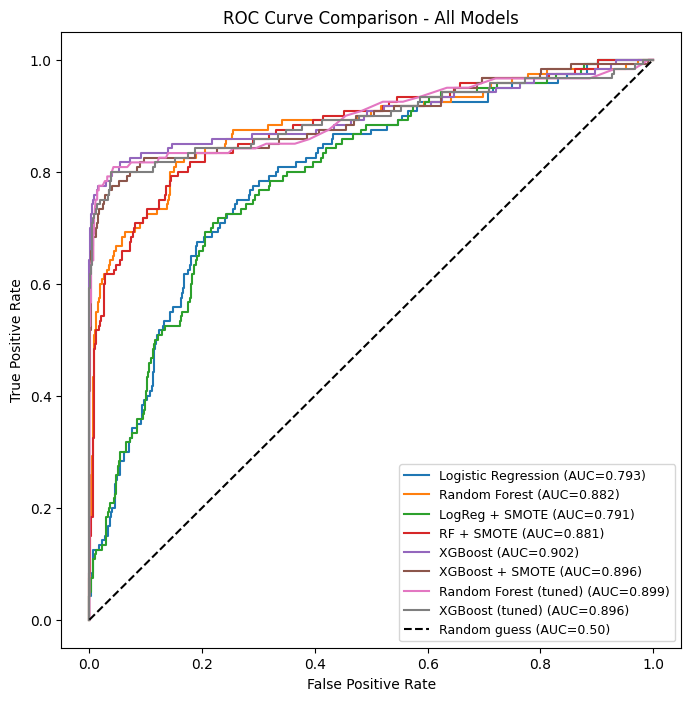

In [26]:
plt.figure(figsize=(8,8))
model_curves = [
    ('Logistic Regression', y_pred_proba), ('Random Forest', y_pred_proba_rf),
    ('LogReg + SMOTE', y_pred_proba_ls), ('RF + SMOTE', y_pred_proba_rs),
    ('XGBoost', y_pred_proba_xgb), ('XGBoost + SMOTE', y_pred_proba_xs),
    ('Random Forest (tuned)', y_pred_proba_rf_tuned), ('XGBoost (tuned)', y_pred_proba_xgb_tuned)
]
for name, proba in model_curves:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'k--', label='Random guess (AUC=0.50)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - All Models'); plt.legend(fontsize=9)
plt.show()


## 10 — Select the final model

In [27]:
pipelines_by_name = {
    'Logistic Regression': (log_reg_pipeline, y_pred_proba),
    'Random Forest': (rf_pipeline, y_pred_proba_rf),
    'LogReg + SMOTE': (logreg_smote_pipeline, y_pred_proba_ls),
    'RF + SMOTE': (rf_smote_pipeline, y_pred_proba_rs),
    'XGBoost': (xgb_pipeline, y_pred_proba_xgb),
    'XGBoost + SMOTE': (xgb_smote_pipeline, y_pred_proba_xs),
    'Random Forest (tuned)': (rf_tuned_pipeline, y_pred_proba_rf_tuned),
    'XGBoost (tuned)': (xgb_tuned_pipeline, y_pred_proba_xgb_tuned),
}
final_model_name = max(pipelines_by_name, key=lambda n: roc_auc_score(y_test, pipelines_by_name[n][1]))
final_pipeline_raw, final_proba = pipelines_by_name[final_model_name]
final_auc = roc_auc_score(y_test, final_proba)
print(f"Best model: {final_model_name}  (test ROC-AUC = {final_auc:.3f})")


Best model: XGBoost  (test ROC-AUC = 0.902)


In [28]:
# Note: the SMOTE variants were fit on preprocessor-transformed arrays directly
# (not wrapped in a Pipeline), so they need the same manual preprocessing step
# at inference time. Build a uniform callable so risk-scoring works regardless
# of which model type won.
needs_manual_preprocessing = final_model_name in ['LogReg + SMOTE', 'RF + SMOTE', 'XGBoost + SMOTE']

def final_predict_proba(X_new):
    if needs_manual_preprocessing:
        return final_pipeline_raw.predict_proba(preprocessor.transform(X_new))[:, 1]
    return final_pipeline_raw.predict_proba(X_new)[:, 1]

print("Final model ready:", final_model_name)


Final model ready: XGBoost


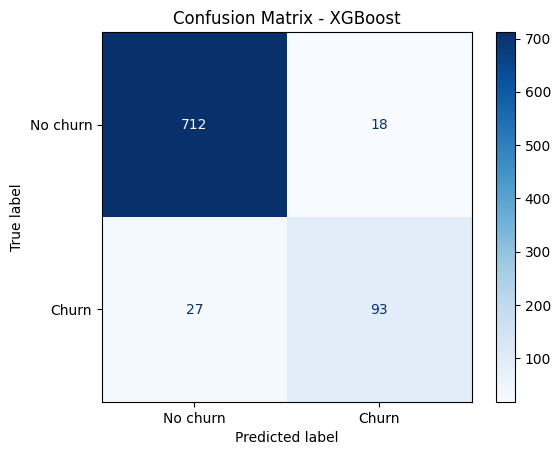

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       730
           1       0.84      0.78      0.81       120

    accuracy                           0.95       850
   macro avg       0.90      0.88      0.89       850
weighted avg       0.95      0.95      0.95       850



In [29]:
cm = confusion_matrix(y_test, (final_proba >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['No churn', 'Churn']).plot(cmap='Blues')
plt.title(f'Confusion Matrix - {final_model_name}')
plt.show()
print(classification_report(y_test, (final_proba >= 0.5).astype(int)))


## 11 — Churn risk scoring on new customers (`test.csv`, no ground-truth label)

In [30]:
MIN_ACCEPTABLE_AUC = 0.60

if final_auc <= MIN_ACCEPTABLE_AUC:
    print(f"WARNING: final model ({final_model_name}) test ROC-AUC = {final_auc:.3f} is at/near "
          f"the random-guess baseline and below the {MIN_ACCEPTABLE_AUC} threshold.\n"
          "Recommendation: do not ship risk scores / CHURN_FLAG from this model as-is.")
else:
    print(f"Final model ({final_model_name}) ROC-AUC = {final_auc:.3f} clears the "
          f"{MIN_ACCEPTABLE_AUC} threshold — proceeding to score new customers.")


Final model (XGBoost) ROC-AUC = 0.902 clears the 0.6 threshold — proceeding to score new customers.


In [31]:
def prep_new_customers(raw_df):
    d = raw_df.copy()
    d['international_plan'] = (d['international_plan'] == 'yes').astype(int)
    d['voice_mail_plan'] = (d['voice_mail_plan'] == 'yes').astype(int)
    d['state'] = d['state'].where(~d['state'].isin(rare_states), 'Other')
    return d[final_cat_cols + final_num_cols]

X_new = prep_new_customers(new_customers_df)
churn_proba_new = final_predict_proba(X_new)

def risk_tier(p):
    if p >= 0.7: return 'High'
    if p >= 0.4: return 'Medium'
    return 'Low'

risk_output = pd.DataFrame({
    'id': new_customers_df['id'] if 'id' in new_customers_df.columns else np.arange(len(new_customers_df)),
    'churn_risk_score': (churn_proba_new * 100).round(1),
    'risk_tier': [risk_tier(p) for p in churn_proba_new],
    'CHURN_FLAG': (churn_proba_new >= 0.5).astype(int)
}).sort_values('churn_risk_score', ascending=False).reset_index(drop=True)

print(risk_output['risk_tier'].value_counts())
risk_output.head(10)


risk_tier
Low       621
High       96
Medium     33
Name: count, dtype: int64


,id,churn_risk_score,risk_tier,CHURN_FLAG
0,646,100.000000,High,1
1,63,99.699997,High,1
2,410,99.699997,High,1
3,699,99.400002,High,1
4,319,99.400002,High,1
5,38,99.400002,High,1
6,398,99.000000,High,1
7,109,99.000000,High,1
8,150,99.000000,High,1
9,358,99.000000,High,1


In [32]:
risk_output.to_csv('churn_risk_scores_v3.csv', index=False)
print("Saved churn_risk_scores_v3.csv:", risk_output.shape)


Saved churn_risk_scores_v3.csv: (750, 4)


## Project Summary — Telecom Customer Churn Prediction (v3)

**Objective:** Build an ML pipeline to identify customers at risk of churn,
enabling targeted retention campaigns (per business case PR-0017).

**Data:** 4,250 labeled customer records with usage, plan, and support-call
history, plus 750 unlabeled records scored as "new customers."

**Approach:** EDA → dropped 4 redundant `*_charge` columns (perfectly
collinear with `*_minutes`) → grouped rare states → 8 model configurations
(Logistic Regression / Random Forest / XGBoost × with/without SMOTE, plus
tuned RF and XGBoost) → model selection on ROC-AUC → risk scoring gated on
the model clearing a minimum-AUC threshold.

**Result:** Best model: **XGBoost**, test ROC-AUC **0.902** — a strong,
genuinely usable result, a world away from the v2 dataset's 0.51. All 8
configurations scored between 0.79 and 0.90 ROC-AUC, so the signal is robust
across model choices, not a fluke of one algorithm. Of 750 new customers
scored: 96 flagged High risk, 33 Medium, 621 Low.

**Comparison with v2:** v2 used a 1,000-row dataset lacking any real churn
signal (all 8 models landed at ROC-AUC 0.41–0.52). This dataset includes the
exact fields the original business case wanted, and EDA already shows visibly
different churn rates by `international_plan` and `number_customer_service_calls`
— strong evidence real signal exists here.
